In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, _, _, match) in pinned.items():
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "061a82116be00c585cab41d5b2a790e2a4f96d44"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/061a82116be00c585cab41d5b2a790e2a4f96d44/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# f-Divergences

Every model in this book that was fitted by maximum likelihood was compared
with its data through one number, the KL divergence.
that section ended on its weak point: it is infinite as
soon as the model gives zero probability to something that occurs. A classifier
rarely notices, because a softmax never outputs an exact zero. A network that
turns a low-dimensional noise vector into an image notices at once, because its
samples lie on a thin surface in image space that can miss the data altogether.
How else can two distributions be compared, and which comparisons can tell a
model that is close from one that is far off?

The smallest case already shows what can go wrong. Let the data sit at a single
point, $P = \delta_0$, and the model's samples at a single point a distance $d$
away, $Q = \delta_d$. A model at $d = 0.01$ is nearly right and one at
$d = 100$ is far off, so a useful loss should tell them apart.
the table shows what five common comparisons report.

<!-- tbl-caption:Five comparisons of the point masses $\delta_0$ and $\delta_d$. The MMD row uses the RBF kernel with length scale $1$. -->

| comparison | $d = 0.01$ | $d = 1$ | $d = 100$ |
|:----|----:|----:|----:|
| KL divergence $D_{\textrm{KL}}(P\|Q)$ | $\infty$ | $\infty$ | $\infty$ |
| Jensen--Shannon divergence | $\log 2$ | $\log 2$ | $\log 2$ |
| total variation distance | $1$ | $1$ | $1$ |
| maximum mean discrepancy $\textrm{MMD}^2$ | $0.0001$ | $0.79$ | $2.00$ |
| Wasserstein distance $W_1$ | $0.01$ | $1$ | $100$ |

Three of the five rows do not change with $d$ at all. A model trained on any of
them receives the same loss at $d = 0.01$ as at $d = 100$, hence no gradient in
$d$. The original generative adversarial network (GAN) of that section
was in this position: its loss is the Jensen--Shannon row up to constants.

The three rows that do not move are of one kind. KL compares $P$ and $Q$
through the ratio $p/q$ of their densities, and if we keep the ratio and change
the function applied to it we obtain a family, the *f-divergences*. Its members
share one proof of non-negativity, one way of being estimated from samples, and
one reason for being blind to $d$. The two rows that move are built without the
ratio and wait for that section.

Once the family is built we ask three questions that the main text keeps
meeting. Does it matter which distribution comes first in KL, the data as in
maximum likelihood or the model as in variational inference
(that section)? What does a small divergence promise to
someone who tries to tell $P$ from $Q$ (that section)? And what
can be computed when both distributions are known only through samples
(that section)? that section ended on
this last question, and adversarial training rests on its answer.

All logarithms are natural, so KL and Jensen--Shannon are in nats. Throughout,
$P$ is the data or the target and $Q$ the model, $p$ and $q$ are their
probability mass functions or densities, and $u = p/q$ is their *density
ratio*.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

In [2]:
from scipy import integrate, optimize

The table is computed. The next cell treats $\delta_0$ and $\delta_d$ as the
probability vectors $(1, 0)$ and $(0, 1)$ on the two points $\{0, d\}$ and
evaluates each row from its definition. Three of the definitions follow in this
section and two in the next.

In [3]:
def kl_div(p, q):
    """D_KL(P||Q) on a finite support: 0 log 0 = 0, and inf if q = 0 < p."""
    s = p > 0
    with np.errstate(divide='ignore'):
        return np.sum(p[s] * np.log(p[s] / q[s]))

def five_comparisons(atoms, p, q, ell=1.0):
    """KL, JS, TV, RBF MMD^2 and W1 between pmfs p, q on sorted atoms."""
    m = (p + q) / 2                                   # the mixture for JS
    K = np.exp(-(atoms[:, None] - atoms[None, :]) ** 2 / (2 * ell ** 2))
    F_gap = np.abs(np.cumsum(p) - np.cumsum(q))[:-1]  # |F_P - F_Q| between atoms
    return {'KL': kl_div(p, q), 'JS': (kl_div(p, m) + kl_div(q, m)) / 2,
            'TV': np.abs(p - q).sum() / 2, 'MMD^2': (p - q) @ K @ (p - q),
            'W1': np.sum(F_gap * np.diff(atoms))}

delta_0, delta_d = np.array([1.0, 0.0]), np.array([0.0, 1.0])  # on atoms (0, d)
for d in (0.01, 1.0, 100.0):
    vals = five_comparisons(np.array([0.0, d]), delta_0, delta_d)
    print(f'd = {d:6}: ' + '  '.join(f'{k} {v:.4g}' for k, v in vals.items()))

d =   0.01: KL inf  JS 0.6931  TV 1  MMD^2 0.0001  W1 0.01
d =    1.0: KL inf  JS 0.6931  TV 1  MMD^2 0.7869  W1 1
d =  100.0: KL inf  JS 0.6931  TV 1  MMD^2 2  W1 100


## The f-Divergence Family

Before we generalize KL we fix what a comparison of two distributions has to
satisfy. The family then comes from asking what the proof that KL is never
negative used.

### Divergences and Metrics

The least that a "distance between distributions" must do is to be zero for
equal distributions and positive for unequal ones. A **divergence** is a
function of two distributions with this property:

$$
D(P, Q) \geq 0, \qquad D(P, Q) = 0 \quad \textrm{if and only if} \quad P = Q.
$$

Nothing else is required. A **metric**, like the distance
$\|\mathbf{x} - \mathbf{y}\|$ between two vectors
(that section), must in addition be symmetric,
$D(P, Q) = D(Q, P)$, and satisfy the triangle inequality,
$D(P, R) \leq D(P, Q) + D(Q, R)$. The KL divergence is a divergence: Gibbs'
inequality (that section) says that
$D_{\textrm{KL}}(P\|Q) \geq 0$, with equality only for $P = Q$. It fails both
extra conditions, and two Gaussians on the line show the failures with numbers.
That section gave the KL divergence between them,

$$
D_{\textrm{KL}}\big(\mathcal{N}(\mu_1, \sigma_1^2) \,\big\|\, \mathcal{N}(\mu_2, \sigma_2^2)\big)
= \log\frac{\sigma_2}{\sigma_1} + \frac{\sigma_1^2 + (\mu_1 - \mu_2)^2}{2\sigma_2^2} - \frac{1}{2}.
$$

For $P = \mathcal{N}(0, 1)$ and $Q = \mathcal{N}(0, 4)$ it gave
$D_{\textrm{KL}}(P\|Q) \approx 0.318$ nats but
$D_{\textrm{KL}}(Q\|P) \approx 0.807$ nats, so KL is not symmetric. The
triangle inequality fails for a different reason. For
unit-variance Gaussians centered at $0$, $1$ and $2$ the formula gives
$D_{\textrm{KL}} = \tfrac{1}{2}$ for each adjacent pair but $2$ for the outer
pair, and $2 > \tfrac{1}{2} + \tfrac{1}{2}$. KL grows like the *square* of the
distance between the means, and squared distances do not satisfy the triangle
inequality.

Neither failure needs repair. Minimizing a divergence uses neither property,
and the asymmetry turns out to be a modeling decision
(that section). A proof that has to chain two comparisons,
from $P$ to $Q$ and from $Q$ to $R$, does need the triangle inequality, and for
it the family we are about to build also contains metrics.

### The f-Divergence Template

Gibbs' inequality is the reason KL is a divergence. Which properties of KL did
its proof use, and what else has them?

First, we write KL as an average under $Q$ of a function of the ratio
$u(x) = p(x)/q(x)$:

$$
D_{\textrm{KL}}(P\|Q) = \sum_x p(x) \log\frac{p(x)}{q(x)}
= \sum_x q(x)\, \frac{p(x)}{q(x)} \log\frac{p(x)}{q(x)}
= \mathbb{E}_{x \sim Q}\big[u(x) \log u(x)\big].
$$

KL weighs each outcome by $Q$ and gives it the penalty $u \log u$. Our running
pair is the one that that section carried through its
examples, $P = (0.6, 0.3, 0.1)$ and $Q = (0.2, 0.5, 0.3)$. Its ratios are
$u = 3$, $0.6$ and $\tfrac13$, with weights $0.2$, $0.5$ and $0.3$:

$$
0.2\,(3 \log 3) + 0.5\,(0.6 \log 0.6) + 0.3\,\big(\tfrac13 \log \tfrac13\big)
= 0.659 - 0.153 - 0.110 = 0.396 \textrm{ nats},
$$

the KL divergence computed in that section.

Second, we look at the proof. that section applied
Jensen's inequality once, to $-\log(q/p)$ under $P$. Run instead under $Q$, on
the function $u \log u$, the same one-step argument needs only two facts about
that function: it is convex, and it is zero at $u = 1$. Third, we replace
$u \log u$ by any function with these two properties. Let
$f : (0, \infty) \to \mathbb{R}$ be convex with $f(1) = 0$, and set
$f(0) = \lim_{u \downarrow 0} f(u)$, which may be $+\infty$. Assume for now
that $p(x) = 0$ wherever $q(x) = 0$, which we write $P \ll Q$, so that an
average under $Q$ sees all of $P$. The **f-divergence** of $P$ with respect to
$Q$ is [@Csiszar.1967]

$$
D_f(P\|Q) = \mathbb{E}_{x \sim Q}\!\left[ f\!\left( \frac{p(x)}{q(x)} \right) \right].
$$

The ratio says, point by point, how much $P$ over- or under-represents $x$
relative to $Q$, and $f$ sets the penalty, which is zero at $u = 1$. We call
$f$ the *divergence function*. The literature calls it the generator of the
divergence, and the code below keeps the functions in a dictionary named
`generators`. In the text, as in that section, a generator is
always a network that produces samples.

One more definition is needed to say when the divergence vanishes. We call $f$
*strictly convex at $1$* if some line through $(1, 0)$ lies strictly below $f$
away from $1$: $f(u) > c\,(u - 1)$ for all $u \neq 1$ and some slope $c$.

**Proposition (non-negativity).** *For any convex $f$ with $f(1) = 0$ and
$P \ll Q$,*

$$
D_f(P\|Q) \geq 0,
$$

*and if $f$ is strictly convex at $1$, then $D_f(P\|Q) = 0$ if and only if
$P = Q$.*

**Proof.** Jensen's inequality (that section) says that
$\mathbb{E}[f(U)] \geq f(\mathbb{E}[U])$ for a convex $f$ and a random variable
$U$. Apply it to $U = u(x)$ with $x \sim Q$. Everything rests on one fact: the
ratio averages to one under $Q$,
$\mathbb{E}_Q[u] = \sum_x q(x)\, p(x)/q(x) = \sum_x p(x) = 1$. Hence

$$
D_f(P\|Q) = \mathbb{E}_Q[f(u)] \geq f(\mathbb{E}_Q[u]) = f(1) = 0.
$$

For the equality case, take the line $c\,(u-1)$ below $f$. Then
$D_f(P\|Q) \geq \mathbb{E}_Q[c\,(u - 1)] = 0$, and the gap is the average of
$f(u) - c\,(u - 1)$, which is positive wherever $u \neq 1$. So $D_f = 0$ forces
$u(x) = 1$ at every $x$ with $q(x) > 0$, that is, $P = Q$. $\blacksquare$

The fact that carried the proof, $\mathbb{E}_Q[u] = 1$, has a second
consequence that we shall use several times. Adding a multiple $c\,(u - 1)$ to
$f$ changes no divergence, because $\mathbb{E}_Q[c\,(u - 1)] = 0$. The
functions $u \log u$ and $u \log u - u + 1$, for instance, both define KL.

The definition assumed $P \ll Q$, and the point masses of the opening violate
it. A generative model begins training in just this regime, with its samples
and the data in disjoint regions, so we must say what $D_f$ means there.
Outcomes with $p(x) = q(x) = 0$ contribute nothing. Where $p(x) = 0 < q(x)$,
the term is $q(x)\, f(0)$, as the definition already says. Where
$q(x) = 0 < p(x)$ the ratio is infinite, and we take the term to be the limit
of $q\, f(p/q)$ as $q \downarrow 0$. With $t = p/q$ the term is $p\, f(t)/t$,
so the limit is $p(x)\, f'(\infty)$ with
$f'(\infty) := \lim_{t \to \infty} f(t)/t$. For a convex $f$ the ratio $f(t)/t$
and the slope $f'(t)$ have the same limit, hence the notation. Both $f(0)$ and
$f'(\infty)$ may be $+\infty$.

On the point masses $\delta_0$ and $\delta_d$ with $d \neq 0$, the outcome $0$
has $q = 0 < p = 1$ and the outcome $d$ has $p = 0 < q = 1$, so

$$
D_f(\delta_0 \| \delta_d) = f(0) + f'(\infty) \qquad \textrm{for every } d \neq 0.
$$

The distance $d$ does not appear on the right, and this says more than the
table did: every f-divergence is constant on disjoint supports. It cannot tell
a near miss from a distant one, and a model trained on it receives no gradient
from the distance between the supports. For KL, $u \log u$ has $f(0) = 0$ and
$f'(\infty) = \lim_{t \to \infty} \log t = \infty$, the first row of
the table. The other two rows that do not move follow
as soon as we have their functions.

### Common Divergence Functions

Each row of the table is one choice of $f$, and
the figure plots the curves. The column $f''(1)$, the
curvature at $u = 1$, is needed in the next subsection.

<!-- tbl-caption:Common divergence functions. Each row gives the function $f$ of one divergence, its curvature at $u = 1$, and whether the divergence is symmetric and whether it, or its square root, is a metric. -->

| Divergence | $f(u)$ | $f''(1)$ | Symmetric? | Metric? |
|:----|:----|:----|:----|:----|
| Kullback--Leibler (forward) | $u \log u$ | $1$ | no | no |
| reverse KL | $-\log u$ | $1$ | no | no |
| Pearson $\chi^2$ | $(u - 1)^2$ | $2$ | no | no |
| squared Hellinger $d_{\mathrm{H}}^2$ | $(\sqrt{u} - 1)^2$ | $\tfrac12$ | yes | $d_{\mathrm{H}}$ is a metric |
| total variation | $\tfrac{1}{2}\lvert u - 1 \rvert$ | none (corner) | yes | yes |
| Jensen--Shannon | $\tfrac{u}{2} \log u - \tfrac{u+1}{2} \log \tfrac{u+1}{2}$ | $\tfrac14$ | yes | $\sqrt{\textrm{JS}}$ is a metric |
| $\alpha$-divergence ($\alpha \neq 0, 1$) | $\dfrac{u^\alpha-\alpha u+\alpha-1}{\alpha(\alpha-1)}$ | $1$ | only at $\alpha = \tfrac{1}{2}$ | square root at $\alpha = \tfrac{1}{2}$ |

![Six divergence functions, the smooth ones shifted by the multiple $f'(1)(u-1)$, which changes no divergence. Every curve is non-negative and zero at $u=1$. The smooth ones are tangent to zero there, with the curvatures $1, 1, 2, \tfrac12, \tfrac14$ of the table, and total variation has a corner instead. Far from $u=1$ the functions penalize over- and under-representation very differently: reverse KL diverges as $u \to 0$, KL and $\chi^2$ grow superlinearly, and total variation grows linearly.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-f-div-generators.svg)

**Reverse KL** uses $f(u) = -\log u$, since
$\mathbb{E}_Q[-\log(p/q)] = \mathbb{E}_Q[\log(q/p)] = D_{\textrm{KL}}(Q\|P)$.
The asymmetry of KL is therefore a choice of $f$, and the two directions are
two rows of the table. Exercise
1a gives the general
rule for swapping arguments.

**Total variation** uses $f(u) = \tfrac{1}{2}|u - 1|$, and
$\sum_x q(x)\, \tfrac12 |p(x)/q(x) - 1| = \tfrac{1}{2}\sum_x |p(x) - q(x)|$.
We write it $\textrm{TV}(P, Q)$. It is half the $\ell_1$ distance between the
probability vectors, and on the running pair
$\textrm{TV} = \tfrac12(0.4 + 0.2 + 0.2) = 0.4$. What this number means for
anyone who tries to tell $P$ from $Q$ is the subject of
that section. On the point masses its function gives
$f(0) + f'(\infty) = \tfrac12 + \tfrac12 = 1$, the third row of
the table.

**Pearson's $\chi^2$ divergence** uses the parabola $f(u) = (u - 1)^2$, so
that $\chi^2(P\|Q) = \sum_x q(x)\,\big(p(x)/q(x) - 1\big)^2
= \sum_x (p(x) - q(x))^2 / q(x)$. On the running pair it is
$0.16/0.2 + 0.04/0.5 + 0.04/0.3 = 1.0133$. A disagreement counts for more where
$Q$ is small, and the first outcome, with $q = 0.2$, contributes $0.8$ of the
total.

The **Jensen--Shannon divergence** [@Lin.1991] symmetrizes KL through the
even mixture $M = \tfrac{1}{2}(P + Q)$, with mass function $m$:

$$
\textrm{JS}(P, Q)
= \frac{1}{2} D_{\textrm{KL}}(P \,\|\, M)
+ \frac{1}{2} D_{\textrm{KL}}(Q \,\|\, M).
$$

Each distribution is compared with the mixture, which has mass wherever either
one does. Since $p/m = 2p/(p + q) \leq 2$, each KL term is at most $\log 2$. So
JS is symmetric and bounded, $0 \leq \textrm{JS}(P, Q) \leq \log 2$, and it
reaches $\log 2$ only when $P$ and $Q$ have disjoint supports, where $p/m = 2$
wherever $p > 0$. Its square root is a metric [@Endres.Schindelin.2003].
Expanding the equation in the ratio $u$ gives the function in the
table (Exercise 1c).
That function has $f(0) = f'(\infty) = \tfrac12 \log 2$, and the sum is the
second row of the table. The one identity
$D_f(\delta_0\|\delta_d) = f(0) + f'(\infty)$ has now accounted for all three
rows that do not move.

The **squared Hellinger divergence** is
$d_{\mathrm{H}}^2(P, Q) = \sum_x \big(\sqrt{p(x)} - \sqrt{q(x)}\big)^2$. So
$d_{\mathrm{H}}$ is the Euclidean distance between the vectors $\sqrt{p}$ and
$\sqrt{q}$, which is why it is a metric (Exercise
2b).

The table's last row is a family within the family, the
**$\alpha$-divergences** [@Amari.2016], with

$$
f_\alpha(u)=\frac{u^\alpha-\alpha u+\alpha-1}{\alpha(\alpha-1)},
$$

which is convex with $f_\alpha(1) = 0$ and curvature $1$ at $u = 1$ for every
$\alpha \neq 0, 1$. As $\alpha \to 1$ it tends to $u\log u - u + 1$ and as
$\alpha \to 0$ to $-\log u + u - 1$. A multiple of $u - 1$ changes no
divergence, so the two ends are forward and reverse KL. Halfway, at
$\alpha = \tfrac12$, the function is $2(\sqrt{u} - 1)^2$, twice squared
Hellinger, and $\alpha = 2$ gives half of $\chi^2$. One parameter thus leads
from reverse KL through Hellinger to forward KL, and on to $\chi^2$ (Exercise
1d relates the
family to Rényi's divergence).

We now evaluate the first six rows on the running pair, in both argument
orders. KL should print $0.396$ and $0.365$ nats, the two values of
that section, and TV and $\chi^2(P\|Q)$ the values just
found by hand.

In [4]:
def f_divergence(f, p, q):
    """D_f(P||Q) = sum_x q(x) f(p(x)/q(x)); nats for KL/JS, else unitless."""
    return np.sum(q * f(p / q))

generators = {
    'KL':          lambda u: u * np.log(u),
    'reverse KL':  lambda u: -np.log(u),
    'chi^2':       lambda u: (u - 1) ** 2,
    'Hellinger^2': lambda u: (np.sqrt(u) - 1) ** 2,
    'TV':          lambda u: 0.5 * np.abs(u - 1),
    'JS':          lambda u: u / 2 * np.log(u) - (u + 1) / 2 * np.log((u + 1) / 2),
}

p = np.array([0.6, 0.3, 0.1])
q = np.array([0.2, 0.5, 0.3])
for name, f in generators.items():
    print(f'{name:12s} D_f(P||Q) = {f_divergence(f, p, q):.4f}   '
          f'D_f(Q||P) = {f_divergence(f, q, p):.4f}')

KL           D_f(P||Q) = 0.3961   D_f(Q||P) = 0.3653
reverse KL   D_f(P||Q) = 0.3653   D_f(Q||P) = 0.3961
chi^2        D_f(P||Q) = 1.0133   D_f(Q||P) = 0.8000
Hellinger^2  D_f(P||Q) = 0.1862   D_f(Q||P) = 0.1862
TV           D_f(P||Q) = 0.4000   D_f(Q||P) = 0.4000
JS           D_f(P||Q) = 0.0911   D_f(Q||P) = 0.0911


The KL row is asymmetric, and the reverse-KL row is the KL row with its columns
swapped. The $\chi^2$ row is asymmetric too ($1.0133$ against $0.8000$).
Squared Hellinger ($0.1862$), TV ($0.4$) and JS are symmetric, and JS, at
$0.0911$ nats, sits far below its ceiling of $\log 2 \approx 0.693$. Six
divergences have looked at one pair of distributions and returned values from
$0.09$ to $1.01$. Multiply KL by $2$, squared Hellinger by $4$ and JS by $8$,
however, and the three products are $0.79$, $0.74$ and $0.73$. Why should
three different functions of the ratio nearly agree, and where do the factors
come from?

### The Local Quadratic

The functions in the figure differ greatly away from
$u = 1$. Near $u = 1$ they turn out to be one function up to a constant, which
is perhaps the most surprising fact about the family. The rest of the section
does not depend on this subsection, and it can be skipped on a first reading.

A multiple of $u - 1$ changes no divergence, so the value $f(1) = 0$ and the
slope $f'(1)$ carry no information, and the first property that distinguishes
one divergence function from another is the curvature $f''(1)$. Near $u = 1$
every smooth $f$ looks like the parabola
$\tfrac12 f''(1)(u - 1)^2$, and the average of $(u-1)^2$ under $Q$ is the
$\chi^2$ divergence, $\mathbb{E}_Q[(u - 1)^2] = \sum_x (p(x) - q(x))^2/q(x)$.
Let $r = \max_x |u(x) - 1|$ measure how far the ratio strays from $1$.

**Proposition (local quadratic).** *Let $P \ll Q$, let $0 < r < 1$, let $f$ be
three times differentiable on $[1 - r, 1 + r]$ with $|f'''| \leq B$ there, and
let $|u(x) - 1| \leq r$ for every $x$ with $q(x) > 0$. Then*

$$
\left| D_f(P\|Q) - \frac{f''(1)}{2}\, \chi^2(P\|Q) \right|
\leq \frac{B r}{6}\, \chi^2(P\|Q).
$$

**Proof.** Taylor's theorem with remainder gives
$f(u) = f'(1)(u - 1) + \tfrac12 f''(1)(u - 1)^2 + R(u)$ with
$|R(u)| \leq B |u - 1|^3 / 6$, since $f(1) = 0$. Take $\mathbb{E}_Q$ term by
term. The linear term vanishes because $\mathbb{E}_Q[u - 1] = 0$, and with it
the only first-order difference between one $f$ and another. The quadratic term
is $\tfrac12 f''(1)\, \chi^2(P\|Q)$. The remainder obeys
$\mathbb{E}_Q|R| \leq \tfrac{B}{6}\,\mathbb{E}_Q|u - 1|^3 \leq \tfrac{B r}{6}\, \mathbb{E}_Q(u - 1)^2 = \tfrac{B r}{6}\,\chi^2$.
$\blacksquare$

So $D_f \approx \tfrac12 f''(1)\, \chi^2$ with a relative error proportional to
$r$: close to $Q$, all smooth f-divergences are multiples of one another. The
factors $2$, $4$ and $8$ that we applied to KL, squared Hellinger and JS are
$2/f''(1)$, and the number that the three products approximate is
$\chi^2(P\|Q) = 1.013$. They fall about a quarter short of it, which does
not contradict the proposition: the running pair has $r = 2$, because its
largest ratio is $3$, and the hypothesis asks for $r < 1$. To see the
approximation take hold, we move the running pair's $P$ toward $Q$ along the
segment $P_t = Q + t\,(P - Q)$, which multiplies every $u - 1$ by $t$, so that
$r = 2t$. For four divergences we print the ratio
$D_f(P_t\|Q) / \big(\tfrac12 f''(1)\, \chi^2(P_t\|Q)\big)$, which should
approach $1$ at a rate proportional to $t$.

In [5]:
curvature = {'KL': 1.0, 'reverse KL': 1.0, 'Hellinger^2': 0.5, 'JS': 0.25}
for t in (0.5, 0.1, 0.01):
    p_t = q + t * (p - q)                     # moves P_t toward Q as t -> 0
    chi2 = f_divergence(generators['chi^2'], p_t, q)
    ratios = [f_divergence(generators[name], p_t, q) / (c / 2 * chi2)
              for name, c in curvature.items()]
    print(f't = {t:4}: ' + '  '.join(f'{name} {r:.3f}'
                                     for name, r in zip(curvature, ratios)))

t =  0.5: KL 0.844  reverse KL 0.747  Hellinger^2 0.789  JS 0.783
t =  0.1: KL 0.956  reverse KL 0.917  Hellinger^2 0.936  JS 0.935
t = 0.01: KL 0.995  reverse KL 0.990  Hellinger^2 0.993  JS 0.993


At $t = 0.5$ the four divergences are about $75\%$ to $85\%$ of their
quadratics, at $t = 0.1$ more than $91\%$, and at $t = 0.01$ more than $99\%$.
Between the last two rows $t$ falls tenfold and so, nearly, does each
shortfall, as the proposition's factor $r$ predicts. The bound itself is a
worst case. For KL at $t = 0.1$ we have $r = 0.2$ and
$|f'''(u)| = 1/u^2 \leq 1/0.8^2$, so it allows a relative error of about
$10\%$, and the cell shows $4\%$. Smooth f-divergences disagree only about distant
distributions, which is the regime early in training, when the model is far
from the data.

On a parametric family the common quadratic is the Fisher information
$\mathbf{I}(\boldsymbol{\theta}) = \mathbb{E}\big[\nabla_{\boldsymbol{\theta}}
\log q_{\boldsymbol{\theta}}\, \nabla_{\boldsymbol{\theta}} \log
q_{\boldsymbol{\theta}}^\top\big]$ of that section. For
a small step $\mathbf{h}$ the ratio of $q_{\boldsymbol{\theta} + \mathbf{h}}$
to $q_{\boldsymbol{\theta}}$ is
$u \approx 1 + \mathbf{h}^\top \nabla_{\boldsymbol{\theta}} \log q_{\boldsymbol{\theta}}$,
so $\chi^2(q_{\boldsymbol{\theta} + \mathbf{h}}\| q_{\boldsymbol{\theta}}) =
\mathbb{E}[(u - 1)^2] \approx \mathbf{h}^\top \mathbf{I}(\boldsymbol{\theta})\,
\mathbf{h}$, and every smooth $D_f$ has Hessian
$f''(1)\, \mathbf{I}(\boldsymbol{\theta})$ at $\mathbf{h} = \mathbf{0}$. The
natural gradient of that section, which
measures steps by KL, would therefore be the same method under any other
smooth f-divergence. Total variation is the exception. Its divergence function
has a corner at $u = 1$ and no curvature, and Exercise
4b shows
what that changes when $P$ approaches $Q$.

## Forward and Reverse KL

Maximum likelihood, the criterion behind most models in this book, minimizes
KL with the data in the first argument. Variational inference minimizes KL with
the model in the first argument. The two orders are the two KL rows of
the table, and when we fit a model
$Q_{\boldsymbol{\theta}}$, with density $q_{\boldsymbol{\theta}}$, to a target
$P$ that it cannot match, they ask for different things:

* **Forward KL**, $D_{\textrm{KL}}(P \,\|\, Q_{\boldsymbol{\theta}}) = \mathbb{E}_P[\log(p/q_{\boldsymbol{\theta}})]$,
  averages over the *truth*. If $q_{\boldsymbol{\theta}}(x) \to 0$ while
  $p(x) > 0$, the divergence blows up. Forward KL is *zero-avoiding*, or
  *mode-covering*: the model must cover every mode of the data, that is,
  every region where $p$ is concentrated, even if that smears mass over
  regions $P$ never visits.
* **Reverse KL**, $D_{\textrm{KL}}(Q_{\boldsymbol{\theta}} \,\|\, P) = \mathbb{E}_{Q_{\boldsymbol{\theta}}}[\log(q_{\boldsymbol{\theta}}/p)]$,
  averages over the *model*. The model is punished for putting mass where
  the truth has none, while modes it never visits leave the objective
  untouched. Reverse KL is *zero-forcing*, or *mode-seeking*: the model
  concentrates on the mass it can explain.

Which direction to use is seldom a free choice, because each needs something
different. Forward KL needs samples from $P$ and the density of the model, and
minimizing it is maximum likelihood: that section
shows that the average negative log-likelihood is the cross-entropy from the
empirical distribution to the model, which differs from forward KL by a
constant. Reverse KL needs samples from the model and the density of the
target, and a density known only up to its normalizing constant will do.
Variational inference (that section) is in that position.
Its target $P$ is a posterior whose normalizing constant is unknown, and it
minimizes $D_{\textrm{KL}}(Q_{\boldsymbol{\theta}}\|P)$ over approximations
$Q_{\boldsymbol{\theta}}$.

Where samples and densities are available on both sides, the direction is a
decision. A student network distilled from a teacher
(that section) spreads over everything the teacher might say
when the teacher comes first, and keeps to the teacher's likeliest outputs when
the student does. The KL penalty of that section puts the policy
first, which keeps it away from actions that the reference policy never takes.

When the model family contains the target, both directions agree on the answer.
They differ for a *misspecified* family, and the simplest instance is a single
Gaussian fitted to a bimodal target. The forward fit needs no computation.
Forward KL is a constant minus $\mathbb{E}_P[\log q(X)]$, so its minimizer is
the maximum-likelihood Gaussian with $P$ in place of the empirical
distribution, and maximum likelihood in an exponential family matches the
expected sufficient statistics (that section):
$\mu^* = \mathbb{E}_P[X]$ and $(\sigma^*)^2 = \textrm{Var}_P(X)$, provided the
variance is finite. The reverse direction has no such closed form, and it can
have one local optimum per mode.

For the mixture $P = 0.7\,\mathcal{N}(-2, 0.6^2) + 0.3\,\mathcal{N}(2, 0.6^2)$
we can therefore predict the forward fit. Its mean is
$0.7(-2) + 0.3(2) = -0.8$. Its variance is the variance within a component
plus the variance of the component means, which for weights $w_1$, $w_2$ and
means $\Delta$ apart is $w_1 w_2 \Delta^2$:
$0.36 + 0.7 \cdot 0.3 \cdot 4^2 = 3.72$. The reverse fit we leave to a
derivative-free optimizer over $\boldsymbol{\theta} = (\mu, \log\sigma)$,
started once at the origin and once near the minor mode, with each KL evaluated
by quadrature on a grid. For every fit the cell prints the mean, the standard
deviation and both divergences.

fit                             mu  sigma  forward KL  reverse KL
forward-KL fit              -0.800  1.929       0.558       1.274
reverse-KL fit              -1.998  0.603       5.981       0.356
reverse-KL fit, 2nd start   +1.995  0.607      14.534       1.202


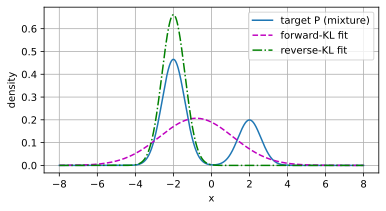

In [6]:
w, mus, sigmas = np.array([0.7, 0.3]), np.array([-2.0, 2.0]), np.array([0.6, 0.6])
x = np.linspace(-8.0, 8.0, 4001)

def log_components(x, w, mus, sigmas):
    """log(w_k N(x; mu_k, sigma_k^2)) for every component k; shape (k, len(x))."""
    return (np.log(w)[:, None] - 0.5 * np.log(2 * np.pi * sigmas[:, None] ** 2)
            - (x - mus[:, None]) ** 2 / (2 * sigmas[:, None] ** 2))

def log_mix(x, w, mus, sigmas):
    """Log-density of the mixture sum_k w_k N(mu_k, sigma_k^2), computed stably."""
    c = log_components(x, w, mus, sigmas)
    c_max = c.max(axis=0)
    return c_max + np.log(np.exp(c - c_max).sum(axis=0))

log_p = lambda x: log_mix(x, w, mus, sigmas)

def log_q(x, theta):
    mu, log_sigma = theta
    return (-0.5 * np.log(2 * np.pi) - log_sigma
            - (x - mu) ** 2 / (2 * np.exp(2 * log_sigma)))

def kl(log_a, log_b, x):
    """D_KL(A||B) by quadrature on the grid x; in nats."""
    return integrate.trapezoid(np.exp(log_a) * (log_a - log_b), x)

fwd = lambda th: kl(log_p(x), log_q(x, th), x)     # D_KL(P || Q_theta)
rev = lambda th: kl(log_q(x, th), log_p(x), x)     # D_KL(Q_theta || P)

th_fwd = optimize.minimize(fwd, x0=[0.0, 0.0], method='Nelder-Mead').x
th_rev = optimize.minimize(rev, x0=[0.0, 0.0], method='Nelder-Mead').x
th_rev2 = optimize.minimize(rev, x0=[2.5, -0.5], method='Nelder-Mead').x

print(f'{"fit":26s}{"mu":>8s}{"sigma":>7s}'
      f'{"forward KL":>12s}{"reverse KL":>12s}')
for name, th in [('forward-KL fit', th_fwd), ('reverse-KL fit', th_rev),
                 ('reverse-KL fit, 2nd start', th_rev2)]:
    print(f'{name:26s}{th[0]:+8.3f}{np.exp(th[1]):7.3f}'
          f'{fwd(th):12.3f}{rev(th):12.3f}')

d2l.plot(x, [np.exp(log_p(x)), np.exp(log_q(x, th_fwd)),
             np.exp(log_q(x, th_rev))], 'x', 'density',
         legend=['target P (mixture)', 'forward-KL fit', 'reverse-KL fit'],
         figsize=(6, 3))

The forward fit lands on the prediction, $\mu = -0.800$ and
$\sigma = 1.929 \approx \sqrt{3.72}$. It is a broad Gaussian draped across both
modes, with substantial mass in the valley between them where $P$ has almost
none. The reverse fit lands at $\mu = -1.998$, $\sigma = 0.603$: it matches the
dominant component and assigns little mass to the minor one. Its reverse KL,
$0.356$ nats, is close to $\log(1/0.7) \approx 0.357$, the divergence of
treating the $70\%$ component as the whole distribution. Started near the minor
mode, the optimizer converges instead to $\mu = +1.995$, where the reverse KL
is $1.202$ nats, close to $\log(1/0.3) \approx 1.204$. Which optimum a
variational method finds therefore depends on its initialization.

Reverse KL is an average under the model, so a mode that the model never
visits is never inspected. All that the objective registers is that the mode it
does visit carries weight $0.7$, or $0.3$, in place of $1$. This is why
variational posteriors tend to be too narrow: here the reverse fit has width
$0.60$ where the target has standard deviation $1.93$.

The last two columns show how differently the two criteria judge the same
omission. Forward KL, the criterion of maximum likelihood, puts the fit on the
dominant mode at $5.98$ nats, more than ten times the $0.558$ of the broad fit,
and the fit on the minor mode at $14.5$. In both, the dropped mode lies more
than six of the model's standard deviations from its mean, where $\log q$ is
very negative (Exercise
3c). Reverse KL ranks the
first two fits the other way, $0.356$ nats against $1.27$: what it penalizes
is the broad fit's mass in the valley, where $P$ has almost none.

The conventions for vanishing densities say the same in the limit. The function
$u \log u$ has $f'(\infty) = \infty$, which gives any mass of $P$ where $Q$ has
none an infinite penalty, and $f(0) = 0$, so that mass of $Q$ where $P$ has
none adds no term at all. For $-\log u$ the two values are exchanged.

## Total Variation, Pinsker's Inequality, and Data Processing

A divergence of $0.4$ says little until we know what it permits and what it
forbids. For total variation the answer is plain, and KL inherits a share of it
through an inequality.

### Total Variation

The function $\tfrac12|u - 1|$ is the plainest in
the table: its penalty is the distance of the ratio
from $1$ and nothing else. Its divergence, half the $\ell_1$ distance between
$p$ and $q$, has a second form that says what the number means. Total variation
is the largest disagreement between $P$ and $Q$ about the probability of any
event $A$:

$$
\textrm{TV}(P, Q) = \frac{1}{2} \sum_x \lvert p(x) - q(x) \rvert
= \sup_{A} \,\lvert P(A) - Q(A) \rvert.
$$

If $\textrm{TV}(P, Q) = 0.03$, then no event distinguishes the two
distributions by more than three percentage points. The supremum is attained at
$A^\star = \{x : p(x) > q(x)\}$, the outcomes that $P$ favors. To see this,
take any event $A$. Then
$P(A) - Q(A) = \sum_{x \in A} (p(x) - q(x)) \leq \sum_{x \in A^\star} (p(x) - q(x))$,
since passing from $A$ to $A^\star$ adds only non-negative terms and removes
only non-positive ones. Because $\sum_x (p(x) - q(x)) = 0$, the positive part
of $p - q$ equals the negative part in magnitude, so the right side is
$\tfrac12 \sum_x |p(x) - q(x)|$, and the same bound holds for $Q(A) - P(A)$.

On the running pair $A^\star$ is the first outcome and
$\textrm{TV} = 0.6 - 0.2 = 0.4$, as before. the figure shows the
same for two densities. TV is a metric: both forms are symmetric, and the
triangle inequality follows from the first (Exercise
2a).

![Two equal-variance densities and the regions where they disagree. The lobe where $p > q$ and the lobe where $q > p$ have the same area, and each equals the total variation distance. The event that attains the supremum is $A^\star = \{p > q\}$, here the half-line left of the crossing: betting on $P$ there and on $Q$ elsewhere is the best single-sample test.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-tv-area.svg)

The second form gives TV its operational meaning. Hand a tester one sample,
drawn from $P$ or from $Q$ with probability $\tfrac12$ each, and ask which
distribution produced it. A test that answers "$P$" when the sample lands in an
event $A$, and "$Q$" otherwise, is right with probability

$$
\tfrac12 P(A) + \tfrac12 \big(1 - Q(A)\big)
= \tfrac12 \big(1 + P(A) - Q(A)\big) \leq \tfrac12 \big(1 + \textrm{TV}(P, Q)\big),
$$

with equality at $A = A^\star$. Every test is of this form for some $A$ (a
randomized test averages such tests and does no better), so the best possible
test beats coin flipping by $\textrm{TV}/2$. On the running pair the best test
answers "$P$" on the first outcome and is right $70\%$ of the time. The
discriminator of a GAN, a network trained to tell data from generated samples,
and a detector of generated text are testers of this kind, and TV limits what
either can achieve from one sample.

### Pinsker's Inequality

TV limits every test, and KL is what we can usually compute or bound, because
it is built from log-probabilities, as losses are. Pinsker's inequality
connects the two: a small KL divergence certifies that no test can tell the
distributions apart well. The trust regions of that section are a case in
point. The guarantee that a policy update improves the return is proved for
total variation and stated as a limit on KL.

**Proposition (Pinsker's inequality).** [@Pinsker.1964; @Csiszar.1967]
*For distributions $P$ and $Q$ on a finite or countable set,*

$$
\textrm{TV}(P, Q) \;\leq\; \sqrt{ \tfrac{1}{2}\, D_{\textrm{KL}}(P\|Q) }.
$$

**Proof.** *Step 1: two outcomes.* Write $\textrm{Ber}(a)$ for a coin that
shows heads with probability $a$. For $a \in [0, 1]$ and $b \in (0, 1)$ the KL
divergence is
$D_{\textrm{KL}}(\textrm{Ber}(a)\|\textrm{Ber}(b)) = a \log\frac{a}{b} + (1-a) \log\frac{1-a}{1-b}$
and the TV distance is $|a - b|$, so we must show that
$\rho(a) = D_{\textrm{KL}}(\textrm{Ber}(a)\|\textrm{Ber}(b)) - 2(a - b)^2$ is
non-negative. Fix $b$. Then $\rho(b) = 0$, the derivative
$\rho'(a) = \log\frac{a}{b} - \log\frac{1-a}{1-b} - 4(a - b)$ vanishes at
$a = b$, and for $0 < a < 1$

$$
\rho''(a) = \frac{1}{a(1-a)} - 4 \geq 0,
$$

since $a(1-a) \leq \tfrac{1}{4}$. A convex function with value and slope zero
at $a = b$ is non-negative, and by continuity (with $0 \log 0 = 0$) also at the
endpoints $a = 0$ and $a = 1$. If $b$ is $0$ or $1$, the divergence is infinite
unless $a = b$, and there is nothing to prove.

*Step 2: reduction to two outcomes.* Let $A^\star = \{p > q\}$, and set
$a = P(A^\star)$, $b = Q(A^\star)$, so that $\textrm{TV}(P, Q) = a - b$.
Merging the outcomes inside $A^\star$ and inside its complement can only
*decrease* KL, by the log-sum inequality: for non-negative numbers $v_i$ and
$w_i$,

$$
\sum_i v_i \log\frac{v_i}{w_i} \geq \big(\sum_i v_i\big) \log \frac{\sum_i v_i}{\sum_i w_i},
$$

itself one application of Jensen to $t \mapsto t\log t$. Applied separately to
the terms in $A^\star$ and in its complement,

$$
D_{\textrm{KL}}(P\|Q) \;\geq\; D_{\textrm{KL}}(\textrm{Ber}(a)\|\textrm{Ber}(b)) \;\geq\; 2(a - b)^2
= 2\,\textrm{TV}(P, Q)^2,
$$

which rearranges to the equation. $\blacksquare$

On the running pair the inequality reads $0.4 \leq \sqrt{0.396/2} = 0.445$,
and Step 2 can be followed by hand. Merging the second and third outcomes
leaves the coins $(0.6, 0.4)$ and $(0.2, 0.8)$. Their TV distance is still
$0.4$, their KL divergence has fallen from $0.396$ to
$0.6 \log 3 + 0.4 \log \tfrac12 = 0.382$ nats, and Step 1 promises at least
$2\,(0.4)^2 = 0.32$.

For a coin of bias $0.6$ against a fair coin the KL divergence is
$0.6 \log 1.2 + 0.4 \log 0.8 = 0.0201$ nats, and Step 1 promises at least
$2\,(0.1)^2 = 0.02$: for nearly equal coins the inequality is nearly an
equality. It has no useful converse, however. A model that assigns $q = 0$ to a
rare event has infinite KL at tiny TV. The bound also goes slack for distant
pairs, since TV is at most $1$: two unit-variance Gaussians $50$ apart have
$\textrm{TV} \approx 1$ but, by the equation, KL
$= 50^2/2 = 1250$ nats.

How tight is the bound for typical pairs, and can the constant $\tfrac12$ be
improved? For the first question we draw $10{,}000$ pairs of distributions on
five outcomes, uniformly from all such distributions. For the second we let
two coins approach each other. Step 1 lost nothing to second order at
$a = b = \tfrac12$, so the ratio $\textrm{TV}/\sqrt{\textrm{KL}/2}$ should
approach $1$ there.

TV / sqrt(KL/2) over 10,000 random pairs: median 0.78, max 0.986
coins 1/2 vs 1/2 +   0.1: TV / sqrt(KL/2) = 0.989881
coins 1/2 vs 1/2 +  0.01: TV / sqrt(KL/2) = 0.999900
coins 1/2 vs 1/2 + 0.001: TV / sqrt(KL/2) = 0.999999


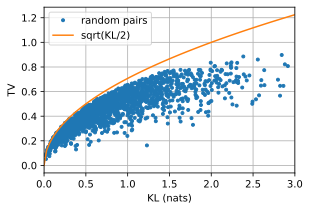

In [7]:
rng = np.random.default_rng()
pr, qr = rng.dirichlet(np.ones(5), 10000), rng.dirichlet(np.ones(5), 10000)
tv = 0.5 * np.abs(pr - qr).sum(axis=1)
kl_pq = np.sum(pr * np.log(pr / qr), axis=1)
ratio = tv / np.sqrt(kl_pq / 2)
print(f'TV / sqrt(KL/2) over 10,000 random pairs: median {np.median(ratio):.2f}, '
      f'max {ratio.max():.3f}')
for delta in (0.1, 0.01, 0.001):
    a, b = np.array([0.5, 0.5]), np.array([0.5 + delta, 0.5 - delta])
    print(f'coins 1/2 vs 1/2 + {delta:5}: TV / sqrt(KL/2) = '
          f'{delta / np.sqrt(kl_div(a, b) / 2):.6f}')
grid = np.linspace(0, 3, 100)
d2l.plot([kl_pq[:2000], grid], [tv[:2000], np.sqrt(grid / 2)], 'KL (nats)',
         'TV', legend=['random pairs', 'sqrt(KL/2)'], fmts=('.', '-'),
         xlim=[0, 3], figsize=(4.5, 3))

In the scatter plot every pair lies below the curve $\sqrt{\textrm{KL}/2}$. The
median pair reaches nearly $0.8$ of the bound, and the largest ratio among the
$10{,}000$ comes within a few hundredths of $1$. Beyond $\textrm{KL} = 2$ the
curve exceeds $1$ and the bound says nothing. For nearly fair coins the ratio
climbs to $0.9899$, $0.9999$ and $0.999999$, so the constant $\tfrac{1}{2}$
cannot be improved (Exercise
4c).
Pinsker's own constant was weaker. The sharp one is due to
@Csiszar.1967 and, independently, to Kullback and to Kemperman.

### Data Processing

Can a feature extractor, a quantizer, or any other processing make two
distributions easier to tell apart? Pinsker's proof merged outcomes and found
that KL can only fall. The same holds for every f-divergence and every kind of
processing. A *channel* $\kappa(y \mid x)$ is any rule, deterministic or
random, that turns an outcome $x$ into an outcome $y$. It maps $P$ to the
output distribution $(P\kappa)(y) = \sum_x \kappa(y \mid x)\, p(x)$, and $Q$
likewise.

**Proposition (data processing for f-divergences).** *For any channel $\kappa$,
convex $f$ with $f(1) = 0$, and $P \ll Q$ on a finite or countable set,*

$$
D_f(P\kappa \,\|\, Q\kappa) \;\leq\; D_f(P\|Q).
$$

**Proof.** Since $\sum_y \kappa(y \mid x) = 1$,
$D_f(P\|Q) = \sum_y \sum_x \kappa(y \mid x)\, q(x)\, f\big(p(x)/q(x)\big)$. Fix
$y$ with $(Q\kappa)(y) > 0$. The weights
$\kappa(y \mid x)\, q(x) / (Q\kappa)(y)$ sum to one over $x$, and averaging the
ratios $p(x)/q(x)$ with these weights gives $(P\kappa)(y)/(Q\kappa)(y)$.
Jensen's inequality therefore bounds the inner sum below by
$(Q\kappa)(y)\, f\big((P\kappa)(y)/(Q\kappa)(y)\big)$, which is the $y$-th term
of $D_f(P\kappa\|Q\kappa)$. An outcome $y$ with $(Q\kappa)(y) = 0$ has
$\kappa(y \mid x) = 0$ wherever $q(x) > 0$, hence also $(P\kappa)(y) = 0$, and
contributes nothing to either side. Summing over $y$ finishes the proof.
$\blacksquare$

No processing of the data, whatever the divergence function, makes two
distributions easier to tell apart. In deep learning the inequality is mostly
read from right to left: a divergence measured on features, on quantized values
or on any other function of the data is a lower bound on the divergence between
the inputs. Merging outcomes, as in Pinsker's proof, is the deterministic
channel $x \mapsto \mathbf{1}(x \in A^\star)$. On the running pair it lowered
KL from $0.396$ to $0.382$, and it lowers $\chi^2$ from $1.013$ to
$0.16/0.2 + 0.16/0.8 = 1$. The case of KL is what that section uses
for mutual information.

A map that can be undone is a channel in both directions, so for it the
inequality is an equality: an f-divergence does not change when the outcomes
are relabeled or the axis is rescaled. The last two rows of
the table do change with the scale. What they gain in
sensitivity to distance they lose in this guarantee.

## The Fenchel Conjugate and the Critic Bound

A network that generates samples gives us draws from its distribution $Q$, and
we hold draws from the data distribution $P$. Neither set of draws tells us the
ratio $p(x)/q(x)$ that the definition the equation needs. Can
$D_f$ be computed from samples alone? It can be bounded from below, and the
bound turns a divergence into a training objective.

### Derivation of the Bound

The tool is the convex conjugate of that section. For
a convex $f$ it is

$$
f^*(t) = \sup_{u}\, \big( ut - f(u) \big),
$$

so that $-f^*(t)$ is the intercept of the tangent line to $f$ with slope $t$
(the figure). For $f(u) = u \log u$ the supremum is
attained where $\log u + 1 = t$, and $f^*(t) = e^{t-1}$. A convex function lies
above each of its tangents, which is the Fenchel--Young inequality

$$
f(u) \geq ut - f^*(t) \quad \textrm{for all } t,
$$

with equality when $t$ is the slope of $f$ at $u$, that is, $t = f'(u)$.

![A convex divergence function, here $f(u)=u\log u$, is the upper envelope of its tangent lines. The tangent of slope $t$ has the intercept $-f^*(t)$, here $-e^{t-1}$. Keeping one tangent gives the Fenchel--Young lower bound, and taking the supremum over slopes recovers the function. Applied at every point to the density ratio, the same inequality gives the critic bound.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-it-f-gan-tangent-bound.svg)

We now apply the inequality *pointwise inside the divergence* and let the slope
vary with $x$. We choose a function $T(x)$, the **critic**, and apply
the equation at $u = p(x)/q(x)$ and $t = T(x)$.

**Proposition (critic bound).** *Let $f$ be convex and
differentiable with $f(1) = 0$, let $P \ll Q$, and let $T$ be any critic with
$\mathbb{E}_P|T| < \infty$ and $\mathbb{E}_Q|f^*(T)| < \infty$. Then*

$$
D_f(P\|Q) \;\geq\; \mathbb{E}_{x \sim P}[T(x)] - \mathbb{E}_{x \sim Q}[f^*(T(x))].
$$

*The supremum of the right side over critics equals $D_f(P\|Q)$, and it is
attained by $T^\star(x) = f'\big(p(x)/q(x)\big)$ wherever $T^\star$ is finite*
[@Nguyen.Wainwright.Jordan.2010; @Nowozin.Cseke.Tomioka.2016].

**Proof.** Multiply the equation at $u = p(x)/q(x)$,
$t = T(x)$ by $q(x) \geq 0$:

$$
q(x)\, f\!\left(\frac{p(x)}{q(x)}\right)
\;\geq\; p(x)\, T(x) - q(x)\, f^*(T(x)).
$$

Summing (or integrating) over $x$ gives the equation. Since
Fenchel--Young holds with equality at $t = f'(u)$, the choice
$T^\star(x) = f'(p(x)/q(x))$ makes the inequality an equality at every $x$,
hence in expectation. $\blacksquare$

Both expectations on the right of the equation are averages, of
$T$ over the data and of $f^*(T)$ over the model's samples, and neither needs a
density. A neural network $T$ can therefore be trained on minibatches to
maximize the bound. For KL the bound reads
$D_{\textrm{KL}}(P\|Q) \geq \mathbb{E}_P[T] - \mathbb{E}_Q[e^{T - 1}]$ for
every critic. The **f-GAN** of @Nowozin.Cseke.Tomioka.2016, after
which the bound is also called the f-GAN bound, makes a game of it. The critic
maximizes the bound, which equals the divergence at the optimal critic, while
the generator, the network that produces the samples of $Q$, minimizes it.
that section trains such pairs.

### The Original GAN

The original GAN of @Goodfellow.Pouget-Abadie.Mirza.ea.2014 is the case
$f(u) = u\log u - (u+1)\log(u+1)$. Its conjugate is $f^*(t) = -\log(1 - e^t)$
for $t < 0$, and writing the critic as the logarithm of a discriminator $D$
with values in $(0, 1)$, $T = \log D$, turns the bound into the familiar
objective

$$
\mathbb{E}_P[T] - \mathbb{E}_Q[f^*(T)]
= \mathbb{E}_{x \sim P}[\log D(x)] + \mathbb{E}_{x \sim Q}[\log(1 - D(x))].
$$

The optimal critic $f'(p/q) = \log\big(p/(p+q)\big)$ is the discriminator
$D^\star = p/(p + q)$. With $f_{\textrm{JS}}$ the Jensen--Shannon function of
the table, this $f$ equals
$2 f_{\textrm{JS}}(u) - (u - 1)\log 2 - \log 4$: twice the Jensen--Shannon
function, a multiple of $u - 1$, which changes no divergence, and the constant
$f(1) = -\log 4$, which only shifts the value. At $D^\star$ the game is
therefore worth $2\,\textrm{JS}(P, Q) - \log 4$, on the running pair
$2(0.0911) - 1.386 = -1.204$.

### Limits of the Bound

The bound has two limits in practice, and the first can be measured. It is
tight only at the optimal critic, so a critic that is not fully trained reports
less than the divergence. To see how much less, we train one.

On the running pair expectations are sums, and a critic is three numbers, one
per outcome. We take $\chi^2$, with $f(u) = (u-1)^2$, conjugate
$f^*(t) = t + t^2/4$ and optimal critic $T^\star = 2(p/q - 1)$. (The conjugate
takes the supremum over all real $u$; Exercise
7a derives it and
shows that this loses nothing at $T^\star$.) The critic starts at $T = 0$,
where the bound is $0$, and takes gradient ascent steps of size $1$ on the
bound, whose derivative with respect to $T(x)$ is
$p(x) - q(x)\,\big(1 + T(x)/2\big)$. The proposition says where the run must
end: at $\chi^2(P\|Q) = 1.0133$, approached from below. The last line of the
cell evaluates a critic that points the right way and is twice too confident,
$2T^\star$.

exact chi^2(P||Q) = 1.0133
steps        0       1       2       5      10      20      50
bound   0.0000  0.2240  0.3935  0.7036  0.9107  1.0013  1.0133
overconfident critic 2 T*: bound = 0.0000


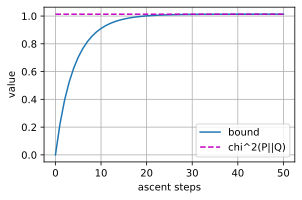

In [8]:
def fgan_bound(T, p, q, f_star):
    """E_P[T] - E_Q[f*(T)]: a lower bound on D_f(P||Q) for any critic T."""
    return np.sum(p * T) - np.sum(q * f_star(T))

chi2_star = lambda t: t + t ** 2 / 4    # conjugate of f(u) = (u - 1)^2
exact = f_divergence(generators['chi^2'], p, q)
T, bounds = np.zeros(3), []             # untrained critic: one number per outcome
for step in range(51):
    bounds.append(fgan_bound(T, p, q, chi2_star))
    T = T + (p - q * (1 + T / 2))       # ascent step 1 along p - q f*'(T)
shown = (0, 1, 2, 5, 10, 20, 50)
print(f'exact chi^2(P||Q) = {exact:.4f}')
print('steps ' + ''.join(f'{s:8d}' for s in shown))
print('bound ' + ''.join(f'{bounds[s]:8.4f}' for s in shown))
T_star = 2 * (p / q - 1)                # the optimal critic f'(p/q)
print(f'overconfident critic 2 T*: bound = '
      f'{fgan_bound(2 * T_star, p, q, chi2_star):.4f}')
d2l.plot(np.arange(51), [bounds, [exact] * 51], 'ascent steps', 'value',
         legend=['bound', 'chi^2(P||Q)'], figsize=(4.5, 2.8))

After five steps the critic certifies $0.70$ of the $1.01$, about $70\%$ of the
divergence, after ten steps $90\%$, and after twenty $99\%$. At no step does
the bound exceed the exact value. The overconfident critic reports zero, no
more than the untrained one. With exact expectations, as here, an adversarial
estimate of a divergence is therefore an underestimate, by an amount that the
estimate itself does not reveal. With averages over samples it remains one, on
average, only for samples that the critic was not trained on (Exercise
8d).

The update also tells us where the missing part hides. It moves $T(x)$ at a
rate proportional to $q(x)$, so the critic is slowest to learn where the
model's samples are rare. On the running pair that is the first outcome, where
the ratio is largest and most of the divergence lies (Exercise
7b).

The second limit is the constancy on disjoint supports, now seen from the
critic's side. If we extend $T^\star = f'(p/q)$ formally beyond the
proposition's hypothesis $P \ll Q$, the ratio is $\infty$ on the data and $0$
on the model's samples, so $T^\star$ is the constant $f'(\infty)$ on one
support and $f'(0)$ on the other. The generator is updated through the
gradient of the critic at the generated samples, and a critic that is constant
there has gradient zero. The generator learns nothing about which way to move.

Both limits have one source, the ratio $p/q$. Samples do not supply it, and
where the supports separate it is $0$ or $\infty$ and keeps no trace of the
distance between them. that section asks what can
be compared without it.

## Summary

The KL divergence is one member of a family: an f-divergence averages a convex
function of the density ratio $p/q$ under $Q$. Jensen's inequality makes every
member non-negative, near $P = Q$ all smooth members agree up to the curvature
$f''(1)$, and none of them grows when the data are processed. The direction of
KL is a modeling decision: forward KL, which maximum likelihood minimizes,
covers every mode, and reverse KL, which variational inference minimizes, can
settle on one. The best test that sees one sample is right with probability
$\tfrac12(1 + \textrm{TV})$, and TV is at most $\sqrt{D_{\textrm{KL}}/2}$. A
critic bounds any f-divergence from below by two averages, one over each
distribution, which is how adversarial training estimates a divergence without
densities. The weakness of the family is the ratio itself: on disjoint supports
every f-divergence is the constant $f(0) + f'(\infty)$, however near or far
the supports are.

## Exercises

1. **Divergence functions and argument order.** Each row of
   the table is one choice of $f$ in the
   template the equation.
    1. For a divergence function $f$, define $f^\diamond(u) = u\, f(1/u)$. Show that
       $f^\diamond$ is convex with $f^\diamond(1) = 0$ and that
       $D_f(Q\|P) = D_{f^\diamond}(P\|Q)$. Compute $f^\diamond$ for the KL
       function $u \log u$ and for the $\chi^2$ function $(u - 1)^2$, and
       write the divergence that the second one defines as a sum over $x$.
    1. Adding $c\,(u - 1)$ to $f$ does not change the divergence.
       Show that $D_f$ is symmetric whenever
       $f^\diamond(u) = f(u) + c\,(u - 1)$ for some constant $c$. Check this
       condition for the rows of the table that are
       marked symmetric, and show that
       $D_{f_\alpha}(Q\|P) = D_{f_{1-\alpha}}(P\|Q)$ for the
       function the equation. Use this identity to
       confirm the entry of the $\alpha$-divergence row in the "Symmetric?"
       column.
    1. Expand the equation in terms of the ratio $u = p/q$ and
       recover the Jensen--Shannon
       function of the table.
    1. *Rényi divergence.* For $\alpha > 0$, $\alpha \neq 1$, define
       $D_\alpha(P\|Q) = \frac{1}{\alpha - 1} \log \sum_x p(x)^\alpha\,
       q(x)^{1-\alpha}$ [@Renyi.1961]. Show that
       $\sum_x p^\alpha q^{1-\alpha} = 1 + \alpha(\alpha - 1)\,
       D_{f_\alpha}(P\|Q)$ and that $D_\alpha$ is an increasing function of
       $D_{f_\alpha}$. Deduce that $D_\alpha \geq 0$ and that $D_\alpha$
       satisfies the data-processing inequality the equation.
       Find $\lim_{\alpha \to 0} D_\alpha(P\|Q)$, and explain why it is $0$
       whenever $p$ and $q$ are positive on the same outcomes. Why does the
       Rényi family therefore *not* reach reverse KL as $\alpha \to 0$, while
       $D_{f_\alpha}$ does?

1. **Metrics among divergences.** The last column of
   the table records which divergences are
   metrics.
    1. Prove the triangle inequality for TV from its half-$\ell_1$ form.
    1. Show that the Hellinger distance $d_{\mathrm{H}} = \sqrt{d_{\mathrm{H}}^2}$
       is the Euclidean distance between the vectors
       $\big(\sqrt{p(x)}\big)_x$ and $\big(\sqrt{q(x)}\big)_x$, so that
       $d_{\mathrm{H}}$ is a metric. Find three distributions on two outcomes
       for which both $d_{\mathrm{H}}^2$ and JS violate the triangle
       inequality.

1. **Cost of dropping a mode.** A model $Q$ misses part of a data
   distribution $P$.
    1. Let $P = (1 - w)\, Q + w R$ with $0 < w < 1$, where $R$ is a
       distribution on a set to which $Q$ assigns probability zero. Compute
       $D_{\textrm{KL}}(P\|Q)$, $D_{\textrm{KL}}(Q\|P)$,
       $\textrm{TV}(P, Q)$ and $d_{\mathrm{H}}^2(P, Q)$ as functions of $w$.
       Which direction of KL penalizes the missing mass? How do the finite
       divergences behave as $w \to 0$?
    1. Now let
       $P = w_1 \mathcal{N}(m_1, s^2) + w_2 \mathcal{N}(m_2, s^2)$ with
       separation $\Delta = |m_2 - m_1|$, and let the model
       $Q = \mathcal{N}(m_1, s^2)$ keep only the first component. Show that
       $D_{\textrm{KL}}(Q\|P) \leq \log(1/w_1)$ for every $\Delta$, with
       equality in the limit $\Delta \to \infty$, and relate the limit to
       (a). Use the bound to explain the two reverse-KL values, $0.356$ and
       $1.202$ nats, that the fit of a Gaussian to the mixture prints.
    1. Assume that the components are well separated, so that almost every
       $x$ has non-negligible density under at most one of them. Show that
       $D_{\textrm{KL}}(P\|Q) \approx w_2 \Delta^2 / (2 s^2)
       + w_1 \log w_1 + w_2 \log w_2$. Evaluate the approximation for
       the mixture of that experiment, and check it
       with `kl(log_p(x), log_q(x, [-2.0, np.log(0.6)]), x)`. The experiment
       prints two values in its forward-KL column to compare with:
       $5.981$ nats at the reverse-KL fit, whose parameters
       $(-1.998, 0.603)$ are not quite $(-2, 0.6)$, and $0.558$ nats at the
       forward fit.

1. **Local quadratic regime.** The proposition
   the equation bounds the gap between $D_f$ and
   $\tfrac12 f''(1)\, \chi^2$.
    1. Exercise 10b of
       that section finds the order at which the two
       directions of the Gaussian KL divergence first differ. Which property
       of the KL and reverse-KL functions explains that order? Carry the
       Taylor expansion of the proof one term further, and show that the
       ratio which the local-quadratic experiment prints is
       $1 + c\, t\, f'''(1)/f''(1) + O(t^2)$ with
       $c = \mathbb{E}_Q[(u - 1)^3] / \big(3 \chi^2(P\|Q)\big)$, about $0.49$
       for the running pair. Compute $f'''(1)/f''(1)$ for the four functions.
       Why is the shortfall of reverse KL at $t = 0.01$ twice that of KL, and
       why do squared Hellinger and JS print the same value there?
    1. The total-variation function $\tfrac{1}{2}|u - 1|$ has no second
       derivative at $1$. Let $P_t = Q + t\,(P - Q)$ for
       $t \in (0, 1]$. How do $\textrm{TV}(P_t, Q)$ and
       $\chi^2(P_t\|Q)$ scale with $t$? Explain from this why Pinsker's
       inequality the equation bounds TV by the square root of
       KL and not by a multiple of KL.
    1. Let $P$ and $Q$ be coins with heads probabilities $b$ and
       $b + \delta$. Use the proposition to show that
       $D_{\textrm{KL}}(P\|Q) = \delta^2 / \big(2 b (1 - b)\big) + O(\delta^3)$.
       Exercise 7a of
       that section obtains the same expansion
       directly from the Bernoulli KL divergence. The factor
       $1/\big(b(1-b)\big)$ is the Fisher information of the
       coin (that section). Find the limit of
       $\textrm{TV}/\sqrt{D_{\textrm{KL}}/2}$ as $\delta \to 0$, and the
       values of $b$ for which Pinsker's inequality is tight in this limit.
       The coin experiment that follows Pinsker's inequality takes
       $b = \tfrac{1}{2}$ and prints a ratio of $0.999999$ at
       $\delta = 10^{-3}$. Why does the ratio approach $1$ at the rate
       $\delta^2$ and not $\delta$?

1. **Detecting generated text.** A detector receives one text of $n$
   tokens. With probability $\tfrac{1}{2}$ a person wrote it (distribution
   $P$ over texts), and otherwise a language model sampled it (distribution
   $Q$).
    1. Show that no detector is right with probability above
       $\tfrac{1}{2}\big(1 + \textrm{TV}(P, Q)\big)$. Show also that a
       detector which sees only a function of the text, such as its length,
       its word counts or the features of a network, can do no better than
       one that sees the text.
    1. On human text the model's loss exceeds the entropy of the text by
       $\varepsilon$ nats per token, so that
       $D_{\textrm{KL}}(P\|Q) = n \varepsilon$ by the decomposition of the
       cross-entropy in that section. Bound the
       detector's accuracy with Pinsker's inequality. For
       $\varepsilon = 0.02$, what does the bound allow at $n = 1$ and at
       $n = 10$, and from which length on does it allow an accuracy of
       $90\%$?
    1. The bound of (b) limits detection and promises nothing. Let $Q$ be
       $P$ conditioned on avoiding a set of texts that has probability
       $0.02$ under $P$. Compute $\textrm{TV}(P, Q)$,
       $D_{\textrm{KL}}(P\|Q)$ and $D_{\textrm{KL}}(Q\|P)$. What does the
       best detector do, and how often is it right? TV is symmetric, so
       Pinsker's inequality holds with either direction of KL. Which
       direction is the useful one here?

1. **Hellinger bounds and testing.** ● Pinsker's inequality is vacuous
   once $D_{\textrm{KL}} > 2$. Let
   $\textrm{BC}(P, Q) = \sum_x \sqrt{p(x) q(x)} = 1 - \tfrac{1}{2} d_{\mathrm{H}}^2(P, Q)$
   be the Bhattacharyya coefficient.
    1. Prove that $\tfrac{1}{2} d_{\mathrm{H}}^2(P, Q) \leq \textrm{TV}(P, Q)$,
       using $|p - q| = |\sqrt{p} - \sqrt{q}|\,(\sqrt{p} + \sqrt{q})$.
    1. Prove that
       $\textrm{TV}(P, Q) \leq d_{\mathrm{H}}(P, Q) \sqrt{1 - \tfrac{1}{4} d_{\mathrm{H}}^2(P, Q)}$
       with the Cauchy--Schwarz inequality of
       that section, and rewrite the
       bound as $\textrm{TV}^2 \leq 1 - \textrm{BC}^2$.
    1. Use Jensen's inequality to show that
       $\textrm{BC}(P, Q) \geq e^{-D_{\textrm{KL}}(P\|Q)/2}$, and conclude
       the Bretagnolle--Huber inequality
       $\textrm{TV}(P, Q) \leq \sqrt{1 - e^{-D_{\textrm{KL}}(P\|Q)}}$
       [@Bretagnolle.Huber.1978; @Canonne.2022]. For which values of
       $D_{\textrm{KL}}$ is it tighter than the equation?
    1. A test sees $n$ independent samples, all from $P$ or all from $Q$,
       each case with probability $\tfrac{1}{2}$. Use (c) and the
       additivity of KL over independent samples to show that every test
       errs with probability at least $\tfrac{1}{4} e^{-n D_{\textrm{KL}}(P\|Q)}$.
       How many samples does an error probability of at most $\eta$
       require? Why can Pinsker's inequality not give a bound of this kind?

1. **Conjugates and critics.** The critic bound the equation
   needs the conjugate $f^*$ of the divergence function.
    1. Derive the conjugate $f^*(t) = t + t^2/4$ of the $\chi^2$ function
       $f(u) = (u - 1)^2$, taking the supremum over $u \in \mathbb{R}$, and
       its optimal critic $T^\star = 2(p/q - 1)$. Redo the computation over
       the function's domain $u \in (0, \infty)$, and show that the
       supremum is $t + t^2/4$ for $t \geq -2$ and $-1$ for $t \leq -2$.
    1. Use the $\mathbb{R}$-conjugate. Show that for every critic $T$ the
       gap between $\chi^2(P\|Q)$ and the bound equals
       $\tfrac{1}{4} \mathbb{E}_Q\big[(T - T^\star)^2\big]$. Deduce that a
       scaled critic $T = c\,T^\star$ certifies
       $\chi^2(P\|Q)\,(2c - c^2)$, which explains the value that the
       experiment prints for $2T^\star$. Show that one ascent step of the
       experiment multiplies $T(x) - T^\star(x)$ by $1 - q(x)/2$. Which
       outcome of the running pair accounts for most of the gap after ten
       steps, and why? For which step sizes does the ascent converge?
    1. Compute the conjugate of the total-variation function
       $f(u) = \tfrac{1}{2}|u - 1|$ over $u \in (0, \infty)$. Show that
       critics with values in $[-\tfrac{1}{2}, \tfrac{1}{2}]$ suffice to
       maximize the bound, and conclude that
       $\textrm{TV}(P, Q) = \sup_g \big(\mathbb{E}_P[g] - \mathbb{E}_Q[g]\big)$
       over all functions $g$ with $|g| \leq \tfrac{1}{2}$, a supremum of
       the kind that that section studies. Which $g$ attains
       it?

1. [code] **Restricted critics.** ● The bound the equation
   is tight only when the critic class contains the optimal critic. Take
   the $\chi^2$ function with the conjugate $f^*(t) = t + t^2/4$, and
   critics $T_{\boldsymbol{\theta}}(x) = \boldsymbol{\theta}^\top \boldsymbol{\phi}(x)$
   that are linear in a feature vector $\boldsymbol{\phi}(x)$.
   Write $\mathbf{m}_P = \mathbb{E}_P[\boldsymbol{\phi}]$,
   $\mathbf{m}_Q = \mathbb{E}_Q[\boldsymbol{\phi}]$ and
   $\boldsymbol{\Sigma} = \mathbb{E}_Q[\boldsymbol{\phi} \boldsymbol{\phi}^\top]$,
   assumed invertible.
    1. Show that the bound is a concave quadratic in $\boldsymbol{\theta}$,
       maximized at
       $\boldsymbol{\theta}^\star = 2 \boldsymbol{\Sigma}^{-1} (\mathbf{m}_P - \mathbf{m}_Q)$,
       with the value
       $(\mathbf{m}_P - \mathbf{m}_Q)^\top \boldsymbol{\Sigma}^{-1} (\mathbf{m}_P - \mathbf{m}_Q)$.
    1. For affine critics, $\boldsymbol{\phi}(x) = (1, x)$, show that the
       value is $(\mathbb{E}_P[X] - \mathbb{E}_Q[X])^2 / \textrm{Var}_Q(X)$.
       What does the restricted bound certify for $P = \mathcal{N}(0, 1)$
       and $Q = \mathcal{N}(0, 4)$?
    1. Use the features $\phi_k(x) = \mathrm{He}_k\big((x - \mu_Q)/\sigma_Q\big)$
       for $k = 0, \ldots, K$, where $\mathrm{He}_k$ are the probabilists'
       Hermite polynomials (`numpy.polynomial.hermite_e.hermevander`) and
       $\mu_Q$, $\sigma_Q$ are the mean and standard deviation of $Q$.
       Compute $\mathbf{m}_P$, $\mathbf{m}_Q$ and $\boldsymbol{\Sigma}$ by
       quadrature on a grid, and plot the value against $K \leq 10$ for the
       pairs $\big(\mathcal{N}(1, 1), \mathcal{N}(0, 1)\big)$ and
       $\big(\mathcal{N}(0, 1), \mathcal{N}(0, 4)\big)$, together with
       their exact divergences $\chi^2 = e - 1$ and $4/\sqrt{7} - 1$. For the
       first pair the values are partial sums of a familiar series. Explain
       why from the generating function
       $e^{xt - t^2/2} = \sum_k \mathrm{He}_k(x)\, t^k / k!$ and the
       orthogonality of the polynomials: for $Z \sim \mathcal{N}(0, 1)$,
       $\mathbb{E}[\mathrm{He}_j(Z)\, \mathrm{He}_k(Z)]$ is $k!$ if $j = k$
       and $0$ otherwise.
    1. For the second pair, replace the expectations by averages over
       $n = 200$ samples from each distribution and fit
       $\boldsymbol{\theta}^\star$ on these samples. Evaluate the bound on
       the same samples and on $10^5$ fresh samples, averaged over $200$
       repetitions, for $K \in \{2, 4, 6, 8, 10\}$. Which of the two
       evaluations estimates a valid lower bound on $\chi^2$? Why does the
       other one exceed the restricted value of (c) and, for large $K$, even
       $\chi^2$ itself?

[Discussions](https://d2l.discourse.group/t/36835)